# 3.1 · Factor investing in US high yield: value, momentum, size and low risk

> **Needs:** the fixed income research cache from notebook 1.1 (the month-end files of `H0A0`) and the database, where
> every run is registered (equity notebook 3.4 explains the registry, the deflated Sharpe ratio and the hold-out).
>
> **Produces:** five registered runs of the family `credit_factors` (each signal's best fifth); a workbook of the
> results in `data/<database>/research/fixed_income/`.

Do bonds that look cheap, that have done well, that come from small issuers or that are safe earn more than the
index? This notebook tests four credit factors on the **ICE BofA US High Yield Index** the way a credit desk's factor
model does - build the factors, combine them, sort the index into fifths, backtest every fifth, then look at what each
one bet on - with the platform's backtest engine and run registry, on the bonds loaded in notebook 1.1.

| Factor | Intuition | Measured as | Preferred |
|---|---|---|---|
| **Value** | a bond whose spread is wide for what it is tends to tighten | its spread above the spread fitted across the month's bonds on maturity, the 3-month spread change, rating notch and industry (% of the fit) | cheap |
| **Momentum** | credit trends last for months (information reaches bond prices slowly; ratings drift) | the excess return compounded over the six months to a month ago | strong |
| **Size** | small issuers are less followed and less liquid, and pay for it | the issuer's total weight in the index, all its bonds together | small |
| **Low risk** | short, well-rated bonds earn more per unit of risk than the market pays for | half the maturity's percentile among the month's bonds, half the rating's notch | safe |

The **composite** is the weighted mean of the factors' percentiles (weights in the first code cell): value, momentum
and low risk a third each. Size is scored and shown on its own but left out of the composite while the files start
in 2019; it goes back in once ICE's files from 2005 are loaded. After Houweling and van Zundert, *Factor Investing in the Corporate Bond Market* (2017).

**How the notebook is organised**

| Step | What it does |
|---|---|
| 0 | Control panel: every setting in one cell, and the run |
| 1 | The panel: what the files hold, year by year |
| 2 | The factors: when each starts, how alike they rank the bonds |
| 3 | Timing and the benchmarks |
| 4 | Every fifth against the index; the best fifth less the worst; the registered runs |
| 5 | Diagnostics: information coefficients, how bonds move between fifths |
| 6 | Proof that no score reads a later file |
| 7 | Charts |
| 8 - 9 | What the best fifth bets on: industries and ratings |
| 10 | Today's ranking of the index's bonds |
| 11 | The workbook |

**Three principles it keeps.**

1. **The vendor's column names are mapped once**, when the files are loaded (`fir load-ice`, into the canonical
   tables): nothing here reads an ICE header.
2. **Factors plug in.** A factor is a function in `fixed_income_research/strategies/factors.py` and a name in
   `FactorConfig.factors`; ranking, the composite, the books, the backtest and every table pick it up.
3. **Every methodology choice is a setting** in the first code cell, and every setting is recorded with the run.

**Conventions.** Every score is turned so that **higher is better**: fifth 5 holds the most attractive bonds, fifth 1
the least (as the equity notebooks' deciles), so a working signal has a **positive** information coefficient. Returns
are ICE's **excess returns** over duration-matched Treasuries unless `RETURNS` says otherwise: what credit selection
earns, not the government yields every bond of a duration shares.

## Step 0 · Control panel

Everything that can be chosen is here. A run is registered with all of it, and a changed setting is another trial of
the family that deflates every Sharpe ratio of it: choose before looking at the results.

In [1]:
import datetime as dt
from dataclasses import asdict

import pandas as pd
from IPython.display import display

from fixed_income_research.analytics import replication as rp
from fixed_income_research.data.cache import ResearchCache
from fixed_income_research.data.index_data import BANDS, broad_rating, load_index_data
from fixed_income_research.strategies import factor_strategy as fs
from research_core import charts
from research_core.analytics.performance.metrics import performance
from research_core.analytics.signals import evaluation as ev
from research_core.data.db.engine import get_engine
from research_core.settings import get_settings

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()  # every run is registered in research.run, so the number of variants tried is known
MONTHS = 12  # the returns are monthly: twelve periods a year

# Universe and window
INDEX = "H0A0"  # ICE BofA US High Yield (C0A0, investment grade, would need RATING_SCALE = "investment_grade")
START = "2019-07-31"  # the first book: the first month end all four factors have a score (the files begin 2019-01)
END = "2024-12-31"  # the last month end before the hold-out (EQR_HOLDOUT_START): opened once, for a final strategy
OPEN_HOLDOUT = False

# The composite: the weighted mean of the factors' percentiles (only the ratios matter; 0 leaves a factor out of it).
# Size is scored and shown but left out while the files start in 2019 (until ICE's files from 2005 are loaded).
FACTOR_WEIGHTS = {"value": 1 / 3, "momentum": 1 / 3, "size": 0.0, "low_risk": 1 / 3}

# Backtest
QUANTILES = 5  # fifths
WEIGHTING = "equal"  # "equal", or "market_value": a fifth's bonds in proportion to their index weights
RETURNS = "excess"  # "excess" over duration-matched Treasuries, or "total"
COST_BPS = 25.0  # one way, on what is traded: about half a high-yield bond's bid-ask spread

# Factor definitions
MOMENTUM_MONTHS, MOMENTUM_SKIP = 6, 1  # six months of excess return, ending a month before the decision
OAS_CHANGE_MONTHS = 3  # value's spread change, a regressor of the fitted spread
MATURITY_SHARE = 0.5  # low risk: half maturity, half rating
RATING_SCALE = "high_yield"

# Diagnostics and output
DIAG_SIGNAL = "composite"  # whose fifths steps 6, 8 and 9 look inside
TOP_N = 7  # industries shown in step 8
SCREEN_ROWS = 20  # bonds shown in step 10
EXPORT = True  # the workbook of step 11

config = fs.FactorConfig(
    family="credit_factors",
    index=INDEX,
    start=START,
    end=END,
    factors=tuple(FACTOR_WEIGHTS.items()),
    returns=RETURNS,
    quantiles=QUANTILES,
    weighting=WEIGHTING,
    cost_bps=COST_BPS,
    momentum_months=MOMENTUM_MONTHS,
    momentum_skip=MOMENTUM_SKIP,
    oas_change_months=OAS_CHANGE_MONTHS,
    maturity_share=MATURITY_SHARE,
    rating_scale=RATING_SCALE,
    open_holdout=OPEN_HOLDOUT,
)
run = fs.run_factors(cache, config, engine=engine)
TOP, SIGNALS, FACTORS = QUANTILES, list(run.scores), [name for name in run.scores if name != "composite"]
KIND = "in excess of Treasuries" if RETURNS == "excess" else "total return"
print(
    f"{INDEX}: {len(run.dates)} rebalances, {run.dates[0]:%B %Y} to {run.dates[-1]:%B %Y}; returns earned "
    f"{run.benchmark.index[0]:%B %Y} to {run.benchmark.index[-1]:%B %Y} ({len(run.benchmark)} months)"
)
print(f"Composite weights {FACTOR_WEIGHTS}; fifths weighted {WEIGHTING}; {RETURNS} returns; {COST_BPS:.0f} bp one way")
print("Registered as research runs", run.run_ids)

H0A0: 66 rebalances, July 2019 to December 2024; returns earned August 2019 to December 2024 (65 months)
Composite weights {'value': 0.3333333333333333, 'momentum': 0.3333333333333333, 'size': 0.0, 'low_risk': 0.3333333333333333}; fifths weighted equal; excess returns; 25 bp one way
Registered as research runs {'value': 262, 'momentum': 263, 'size': 264, 'low_risk': 265, 'composite': 266}


## Step 1 · The panel

What the cache holds of the index, read up to `END`: one row per month end, the index **after** that day's rebalance
(its members and weights for the month that follows) with what was known of each bond that day - its spread, rating,
maturity, issuer and industry - and its return over the month just ended. The provider's percentages are fractions
here. Each column below is the median month of the year.

In [2]:
data, members = run.data, run.members
present = members.sum(axis=1)
per_month = pd.DataFrame(
    {
        "bonds": present,
        "issuers": data.issuer.where(members).nunique(axis=1),
        "with a spread": data.analytics["oas_bp"].notna().sum(axis=1) / present,
        "with an excess return": data.excess_returns.notna().sum(axis=1) / present,
        "with an industry": data.industry.notna().sum(axis=1) / present,
        "rated CCC and below": (broad_rating(data.rating) == "CCC and below").sum(axis=1) / present,
    }
)
by_year = per_month.groupby(per_month.index.year).median()
by_year.insert(0, "month ends", per_month.groupby(per_month.index.year).size())
calendar = pd.period_range(data.dates[0], data.dates[-1], freq="M")
missing = calendar.difference(data.dates.to_period("M"))
print(
    f"{len(data.dates)} month ends, {data.dates[0]:%B %Y} to {data.dates[-1]:%B %Y}; "
    f"{data.weights.shape[1]:,} bonds have been members; month ends without a file: "
    f"{', '.join(p.strftime('%B %Y') for p in missing) or 'none'}"
)
share = "{:.1%}"
display(
    by_year.rename_axis("year").style.format(
        {"month ends": "{:.0f}", "bonds": "{:,.0f}", "issuers": "{:,.0f}"}
        | {c: share for c in by_year.columns if c.startswith(("with", "rated"))}
    )
)

72 month ends, January 2019 to December 2024; 4,702 bonds have been members; month ends without a file: none


,month ends,bonds,issuers,with a spread,with an excess return,with an industry,rated CCC and below
year,,,,,,,
2019,12,"1,789",846,100.0%,98.2%,100.0%,14.1%
2020,12,"1,978",830,100.0%,97.6%,100.0%,15.4%
2021,12,"2,108",926,100.0%,97.3%,100.0%,13.8%
2022,12,"1,984",926,100.0%,99.5%,100.0%,12.9%
2023,12,"1,871",886,100.0%,98.9%,100.0%,14.2%
2024,12,"1,864",880,100.0%,98.2%,100.0%,14.2%


## Step 2 · The factors

Each factor is measured on every month end from the files dated on or before it, then turned so that higher is better.

**Value** - the spread $s$ of each bond is regressed across the month's bonds on its years to maturity, the change in
its spread over three months, and dummies for its rating notch and its issuer's industry (ICE's level 3). The signal is
how far the actual spread is above the fitted one:

$$\text{value}_{i,t} = \frac{s_{i,t} - \hat s_{i,t}}{\hat s_{i,t}} \times 100$$

Above the fit is cheap. A bond without a spread three months ago (a new issue) has no value score that month.

**Momentum** - the excess return compounded over six months, ending a month before the decision, so the month just
ended - known, but prone to reverse - is left out:

$$\text{mom}_{i,t} = \prod_{k=1}^{6} \left(1 + r_{i,t-k}\right) - 1$$

Months are counted on the calendar: a bond out of the index for one of them, or a month end without a file, has none.

**Size** - minus the issuer's total weight in the index: the smaller the issuer, the higher the score.

**Low risk** - minus a blend, half the bond's maturity percentile among the month's bonds and half its rating's place
on the high-yield scale (BBB3 the safest, C the riskiest); a part a bond lacks takes the month's median.

A fifth of one factor ranks only the bonds that factor scores; in the composite a missing factor counts as average
(the 50th percentile), so a new issue is still ranked by the other three. The table shows when each signal begins and
how much of the index it scores; the matrix how alike two signals rank the bonds (their average Spearman correlation
across the members, month by month): near 1, one adds little to the other.

In [3]:
on = run.dates
coverage = pd.DataFrame(
    {
        "first month end scored": {k: f"{s.notna().any(axis=1).idxmax():%Y-%m-%d}" for k, s in run.scores.items()},
        "share of members scored": {
            k: float((s.loc[on].notna().sum(axis=1) / members.loc[on].sum(axis=1)).median())
            for k, s in run.scores.items()
        },
    }
)
display(coverage.style.format({"share of members scored": "{:.1%}"}))
alike = ev.rank_correlations({k: s.loc[on] for k, s in run.scores.items()}, members=members)
display(alike.style.format("{:+.2f}"))

,first month end scored,share of members scored
value,2019-04-30,92.4%
momentum,2019-07-31,85.6%
size,2019-01-31,100.0%
low_risk,2019-01-31,100.0%
composite,2019-01-31,100.0%


,value,momentum,size,low_risk,composite
value,+1.00,-0.03,+0.09,-0.05,+0.57
momentum,-0.03,+1.00,-0.01,-0.06,+0.54
size,+0.09,-0.01,+1.00,-0.03,+0.02
low_risk,-0.05,-0.06,-0.03,+1.00,+0.56
composite,+0.57,+0.54,+0.02,+0.56,+1.00


## Step 3 · Timing and the benchmarks

**The timing, stated plainly.** A book formed on month end *t* is chosen from the file of *t* and earns month *t+1*'s
return, which is read from the file of *t+1*: the engine's rule that a book set on a date earns from the next one. So
each return is shown on the month it was **earned**, and every statistic is computed on that basis; no relabelling is
needed (step 6 proves that nothing of the file of *t+1* reaches the book of *t*).

**Bonds that leave.** A bond called, matured, upgraded or defaulted at the rebalance of *t+1* is in no file after
*t*, so its return over its last month is unknown. It earns the index's return that month - the neutral guess notebook
2.1 makes - in every book alike, so no fifth gains from it on average (a fifth heavy in defaulters is flattered; see
the limits).

**Benchmarks**, run through the same engine at no cost:

* **the index** at its own weights - exactly notebook 2.1's rebuild (which tracks ICE's published index within 0.08 %
  a year), checked below;
* **all its members equally weighted** - each fifth is equally weighted, so this isolates what the *selection* added
  from what equal weighting alone (a tilt to small issuers) did.

**Costs.** `COST_BPS` one way on the value traded at each rebalance, for the fifths; the tables are after costs unless
they say otherwise.

In [4]:
FMT = {
    "cagr": "{:.2%}",
    "vol": "{:.2%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.1%}",
    "beta": "{:.2f}",
    "alpha": "{:+.2%}",
    "active_return": "{:+.2%}",
    "tracking_error": "{:.2%}",
    "information_ratio": "{:+.2f}",
    "up_capture": "{:.2f}",
    "down_capture": "{:.2f}",
    "turnover": "{:.1f}",
}
raw = data.excess_returns if RETURNS == "excess" else data.total_returns
rebuilt = rp.index_returns(data.weights, raw).reindex(run.benchmark.index)
gap = float((run.benchmark - rebuilt["return"]).abs().max())
print(
    f"The index book against notebook 2.1's rebuild: largest monthly difference {gap:.1e}. On average "
    f"{rebuilt['leavers'].mean():.1%} of the index's weight left each month (most {rebuilt['leavers'].max():.1%}, "
    f"{rebuilt['leavers'].idxmax():%B %Y}) and earned the index's return."
)
yardsticks = pd.DataFrame(
    {
        "Index (by weight)": performance(run.benchmark, periods_per_year=MONTHS),
        "All members, equally weighted": performance(run.equal_weighted.net, periods_per_year=MONTHS),
    }
).T
display(yardsticks.style.format(FMT))

The index book against notebook 2.1's rebuild: largest monthly difference 5.4e-08. On average 1.9% of the index's weight left each month (most 4.3%, November 2023) and earned the index's return.


,cagr,vol,sharpe,max_drawdown
Index (by weight),3.62%,8.82%,0.45,-18.0%
"All members, equally weighted",4.13%,10.34%,0.45,-21.7%


## Step 4 · Every fifth against the index

Each fifth's growth a year (**cagr**), volatility, Sharpe ratio (no risk-free rate: the returns are already in excess
of Treasuries) and worst fall; against the index its **beta**, **alpha** (the return a year left after beta times the
index's), **active return** (how much faster it grew than the index), **tracking error** (the volatility of the
monthly difference), **information ratio** (the mean difference a year over the tracking error), up and down
**capture** (its growth in the index's rising and falling months over the index's), and **turnover** (bought and sold
in a year, as a multiple of the book). All after costs.

First the fan: if a signal sorts the bonds, the active return rises from fifth 1 to fifth 5.

In [5]:
table = fs.quantile_table(run)
fan = fs.fan(table)
display(fan.style.format("{:+.2%}").set_caption("Active return a year against the index, after costs (5 = best)"))
before = fs.fan(fs.quantile_table(run, net=False))
display(before.style.format("{:+.2%}").set_caption("The same before costs"))
print(f"The best fifth of each signal ({TOP} = the bonds it likes most), after costs:")
display(table.xs(TOP, level="fifth").style.format(FMT))

fifth,1,2,3,4,5,5 less 1
signal,,,,,,
value,-2.75%,-2.05%,-1.30%,-2.15%,-2.31%,+0.44%
momentum,-3.98%,-2.41%,-3.75%,-4.29%,+1.05%,+5.03%
size,+0.36%,-0.23%,-1.15%,-0.56%,+1.29%,+0.92%
low_risk,+1.23%,+0.36%,-0.95%,-0.17%,-0.84%,-2.07%
composite,-1.96%,-2.29%,-3.15%,-2.78%,-0.85%,+1.11%


fifth,1,2,3,4,5,5 less 1
signal,,,,,,
value,-1.19%,+0.73%,+1.92%,+0.94%,-0.38%,+0.81%
momentum,-1.74%,+1.19%,+0.06%,-0.80%,+3.27%,+5.01%
size,+0.75%,+0.33%,-0.55%,+0.01%,+1.71%,+0.96%
low_risk,+1.70%,+0.98%,-0.32%,+0.40%,-0.45%,-2.15%
composite,-0.19%,+0.83%,+0.19%,+0.39%,+1.01%,+1.19%


The best fifth of each signal (5 = the bonds it likes most), after costs:


,cagr,vol,sharpe,max_drawdown,beta,alpha,active_return,tracking_error,information_ratio,up_capture,down_capture,turnover
signal,,,,,,,,,,,,
value,1.22%,10.80%,0.17,-23.7%,1.17,-2.81%,-2.31%,3.39%,-0.63,1.05,1.33,7.8
momentum,4.70%,10.68%,0.49,-22.1%,1.12,+0.78%,+1.05%,4.24%,+0.29,1.20,1.11,8.8
size,4.95%,12.32%,0.46,-23.5%,1.23,+0.79%,+1.29%,6.21%,+0.27,1.20,1.08,1.7
low_risk,2.74%,7.28%,0.41,-15.7%,0.81,-0.21%,-0.84%,2.29%,-0.43,0.70,0.72,1.6
composite,2.74%,8.73%,0.36,-19.3%,0.95,-0.65%,-0.85%,2.54%,-0.34,0.86,0.93,7.4


### The best fifth less the worst

The difference between the best and the worst fifth each month, **before costs**, is the cleanest read on whether a
signal sorts bonds the right way: the market's direction cancels out. A long-short book would earn about this, less
its costs and the cost of borrowing bonds. **t** is the mean monthly difference over its standard error; 2 is the
usual bar, and with 65 months it takes a large, steady spread to clear it.

In [6]:
spread = fs.spreads(run)
spread_stats = fs.spread_table(spread)
display(
    spread_stats.style.format(
        {
            "cagr": "{:+.2%}",
            "vol": "{:.2%}",
            "sharpe": "{:+.2f}",
            "positive": "{:.0%}",
            "t": "{:+.2f}",
            "months": "{:d}",
        }
    )
)

,cagr,vol,sharpe,positive,t,months
value,+1.01%,3.73%,+0.29,65%,+0.67,65
momentum,+2.30%,13.29%,+0.24,60%,+0.56,65
size,+1.11%,7.42%,+0.18,51%,+0.43,65
low_risk,-3.05%,7.33%,-0.39,38%,-0.90,65
composite,+0.04%,8.23%,+0.05,57%,+0.11,65


### The registered runs

Each signal's best fifth is the long-only book one could hold, so it is the one registered. The **deflated Sharpe
ratio** is the probability that its Sharpe ratio beats the best of as many no-skill strategies as the family has
tried (*trials*); the **deflated active** one asks the same of its information ratio against the index - the question
that matters for a long-only book, whose own Sharpe ratio mostly measures the market it holds. Below about 95 % the
result is not convincing.

In [7]:
registered = pd.DataFrame(run.metrics).T[
    ["cagr", "sharpe", "active_return", "information_ratio", "trials", "deflated_sharpe", "deflated_active_sharpe"]
]
registered.insert(0, "run", pd.Series(run.run_ids))
display(
    registered.style.format(
        {
            "cagr": "{:.2%}",
            "sharpe": "{:.2f}",
            "active_return": "{:+.2%}",
            "information_ratio": "{:+.2f}",
            "trials": "{:.0f}",
            "deflated_sharpe": "{:.1%}",
            "deflated_active_sharpe": "{:.1%}",
        }
    )
)

,run,cagr,sharpe,active_return,information_ratio,trials,deflated_sharpe,deflated_active_sharpe
value,262,1.22%,0.17,-2.31%,-0.63,5,23.6%,0.2%
momentum,263,4.70%,0.49,+1.05%,+0.29,5,48.2%,30.8%
size,264,4.95%,0.46,+1.29%,+0.27,5,45.9%,28.7%
low_risk,265,2.74%,0.41,-0.84%,-0.43,5,42.4%,1.9%
composite,266,2.74%,0.36,-0.85%,-0.34,6,35.1%,1.7%


## Step 5 · Diagnostics

**Information coefficient (IC)** - each month, the rank correlation across the index's bonds between a signal and the
excess return of the month that follows (bonds that left in between are left out). Its mean says whether the signal
predicts; **t** whether that mean is distinguishable from luck (the months do not overlap, so no Newey-West lags are
needed). Higher is better here, so a **positive** IC means the signal works. **discovery** applies Benjamini and
Hochberg's false-discovery control across the five signals at 10 %; **spread** is the mean monthly best-less-worst
fifth outcome; **turnover** the share of the best fifth replaced each month; **rank autocorrelation** how alike a
signal ranks the bonds one month and the next.

,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,
value,+0.042,+3.42,0.001,True,+0.10%,31%,0.86
low_risk,-0.046,-1.76,0.078,False,-0.24%,5%,1.00
size,+0.028,+1.50,0.132,False,+0.12%,5%,1.00
momentum,+0.033,+1.47,0.143,False,+0.27%,35%,0.73
composite,+0.011,+0.61,0.543,False,+0.03%,30%,0.84


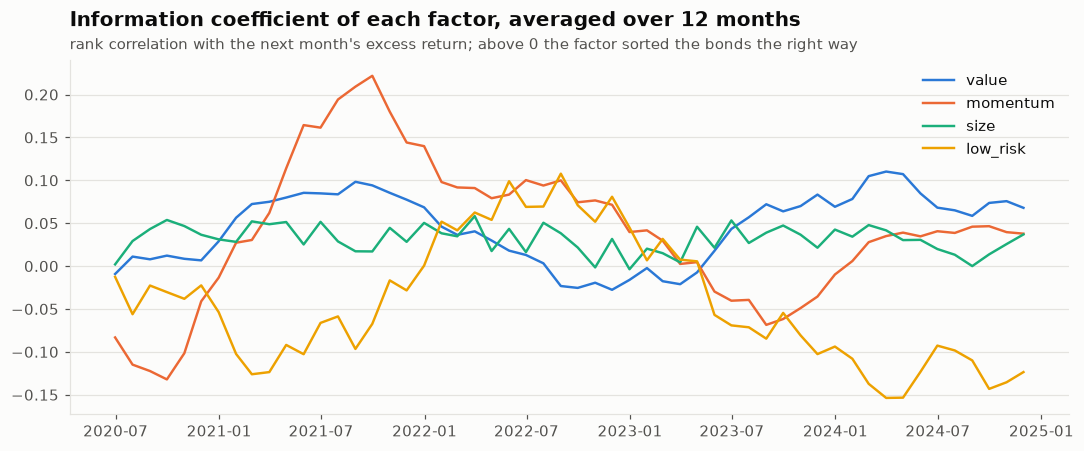

In [8]:
scores_on = {k: s.loc[run.dates] for k, s in run.scores.items()}
ledger = ev.triage(scores_on, run.outcome, members, lags=0, top=1 / QUANTILES)
display(
    ledger.style.format(
        {
            "mean_ic": "{:+.3f}",
            "t_nw": "{:+.2f}",
            "p_value": "{:.3f}",
            "spread": "{:+.2%}",
            "turnover": "{:.0%}",
            "rank_autocorrelation": "{:.2f}",
        }
    )
)
ic = pd.DataFrame({k: ev.ic_series(scores_on[k], run.outcome, members) for k in FACTORS})
fig = charts.lines(
    {k: ic[k].rolling(12).mean() for k in FACTORS},
    "Information coefficient of each factor, averaged over 12 months",
    subtitle="rank correlation with the next month's excess return; above 0 the factor sorted the bonds the right way",
)

**Transitions.** Of the bonds in each fifth of the composite, the share found in each fifth one and three months
later (bonds that left the index in between are left out). A heavy diagonal is a persistent signal whose books change
little from month to month - cheap to hold; a flat table reshuffles and pays for it.

In [9]:
transitions = {
    h: ev.quantile_transitions(scores_on[DIAG_SIGNAL], members, quantiles=QUANTILES, horizon=h) for h in (1, 3)
}
for h, moves in transitions.items():
    display(moves.style.format("{:.1%}").set_caption(f"{DIAG_SIGNAL}: from each fifth to each fifth {h} month(s) on"))

to (+1),1,2,3,4,5
from,,,,,
1,73.3%,19.4%,5.0%,1.7%,0.5%
2,19.0%,49.2%,22.5%,7.3%,1.9%
3,5.3%,21.3%,44.8%,22.5%,6.1%
4,1.7%,6.8%,22.1%,47.9%,21.6%
5,0.3%,1.5%,5.6%,21.2%,71.5%


to (+3),1,2,3,4,5
from,,,,,
1,60.4%,23.2%,10.2%,4.5%,1.7%
2,24.0%,33.3%,24.7%,13.2%,4.9%
3,9.1%,22.2%,31.6%,25.0%,12.1%
4,3.8%,11.1%,23.0%,34.9%,27.3%
5,1.3%,3.9%,10.3%,24.8%,59.8%


## Step 6 · Proof: no score reads a later file

**The worry.** If the score that forms the July book read anything from the August file, July's "prediction" would
already contain the answer and the backtest would be fiction. Value is the factor to watch: its regression runs one
month at a time, and its only backward-looking term is the spread change over three months.

**Check 1 - point in time.** Every signal is computed again after **deleting every month end later than the
formation month**, for one formation month a year. If the scores of that month are the same to the last bit, no later
file reaches them (`max |difference|` 0). The same test runs on a synthetic index in the unit tests.

**Check 2 - timing.** The best composite fifth formed in the middle of the window earns, in the engine, exactly its
bonds' returns in the *next* file: the file of *t+1* supplies only the return the book of *t* earns, never an input
to it.

In [10]:
check = fs.point_in_time_check(run.data, config, run.dates[::12])
display(check.style.format({c: "{:.1e}" for c in check.columns if c != "bonds"}))
worst = float(check.drop(columns="bonds").to_numpy().max())
print(
    "PASS: deleting the later files changes no score"
    if worst == 0
    else f"FAIL: a score moved by {worst:.2e} when the later files were deleted"
)

formed = run.dates[len(run.dates) // 2]
earned_in = run.benchmark.index[run.benchmark.index > formed][0]
book = run.books[DIAG_SIGNAL][TOP].loc[formed]
held = book[book > 0].index
by_hand = float((book[held] * run.returns.loc[earned_in, held].fillna(0.0)).sum())
in_engine = float(run.backtests[DIAG_SIGNAL][TOP].gross.loc[earned_in])
stayed = float(data.weights.loc[earned_in, held].notna().mean())
print(
    f"The best {DIAG_SIGNAL} fifth formed on {formed:%d %B %Y} from that day's file ({len(held)} bonds) earned "
    f"{in_engine:+.4%} in {earned_in:%B %Y} in the engine; by hand from the file of {earned_in:%d %B %Y}: "
    f"{by_hand:+.4%}. {stayed:.1%} of its bonds are in that file; the rest left the index and earned its return."
)

,bonds,value,momentum,size,low_risk,composite
month end,,,,,,
2019-07-31 00:00:00,1790,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
2020-07-31 00:00:00,1975,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
2021-07-31 00:00:00,2107,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
2022-07-31 00:00:00,1972,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
2023-07-31 00:00:00,1869,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
2024-07-31 00:00:00,1858,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00


PASS: deleting the later files changes no score
The best composite fifth formed on 30 April 2022 from that day's file (407 bonds) earned -0.9615% in May 2022 in the engine; by hand from the file of 31 May 2022: -0.9615%. 97.8% of its bonds are in that file; the rest left the index and earned its return.


## Step 7 · Charts

What 100 became in each signal's best and worst fifth, after costs, beside the index and all its members equally
weighted. A signal that sorts the bonds puts its best fifth above the equal-weighted line and its worst below; lines
that cross and recross mean it does not separate them reliably.

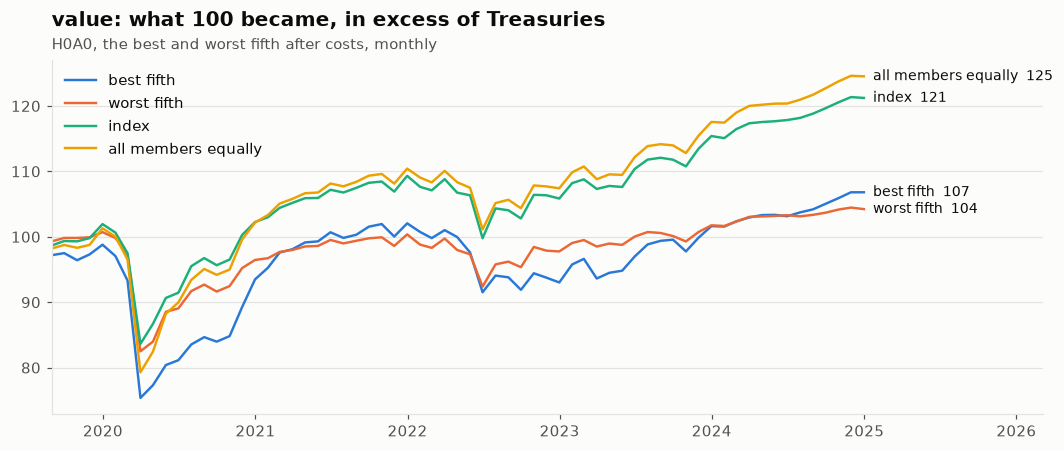

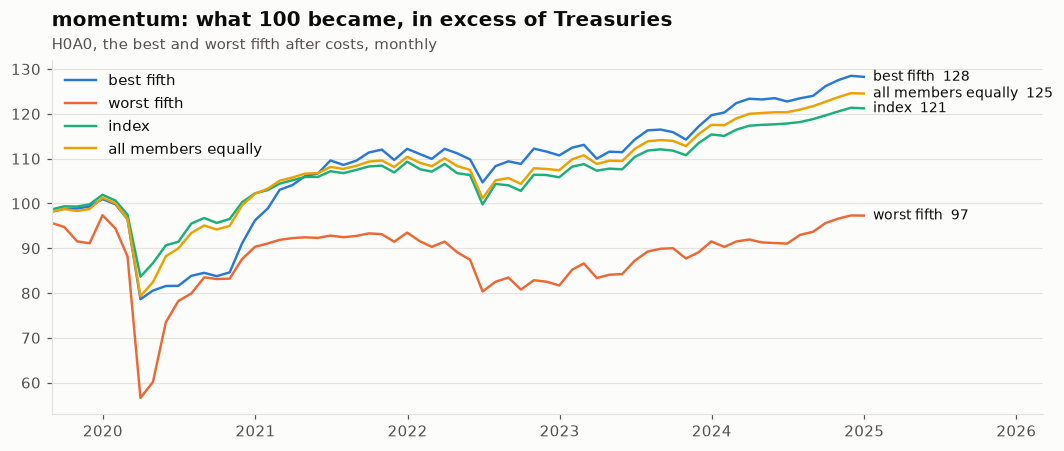

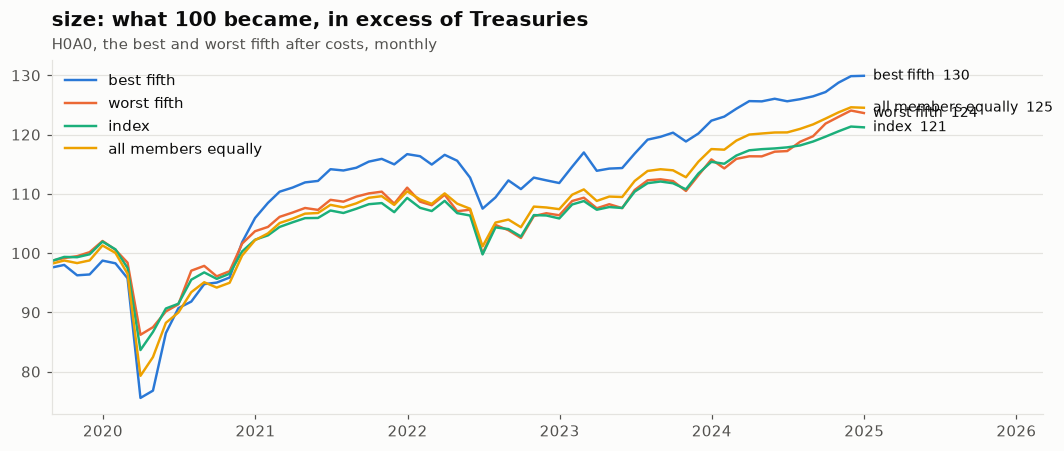

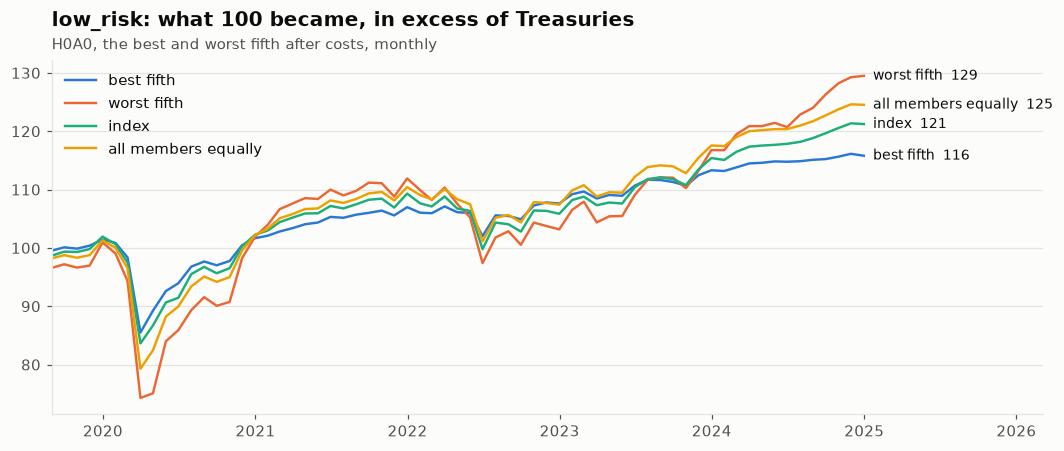

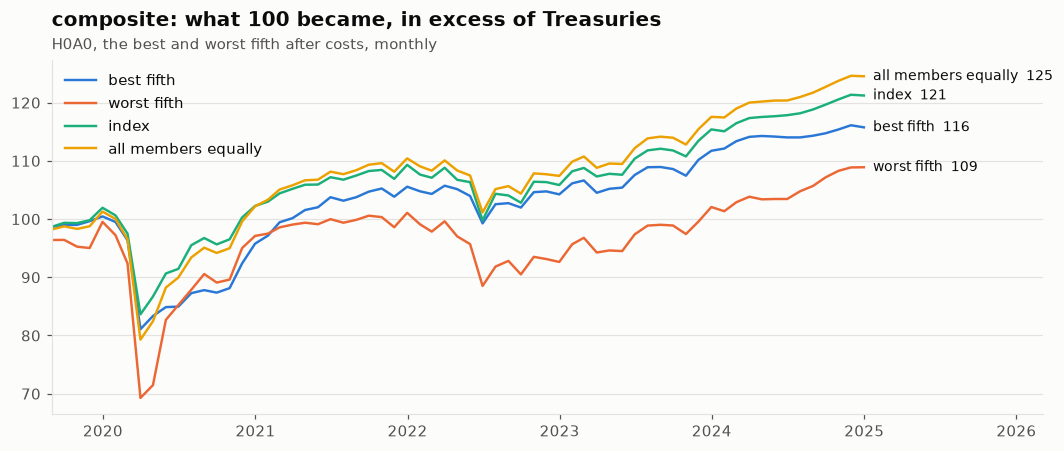

In [11]:
for name in SIGNALS:
    fifths = run.backtests[name]
    fig = charts.growth(
        {
            "best fifth": fifths[TOP].net,
            "worst fifth": fifths[1].net,
            "index": run.benchmark,
            "all members equally": run.equal_weighted.net,
        },
        f"{name}: what 100 became, {KIND}",
        subtitle=f"{INDEX}, the best and worst fifth after costs, monthly",
        log=False,
        symbol="",
    )

The best fifth less the worst, before costs, compounded: a line rising steadily is a factor that kept sorting the
bonds the right way; one that rises in a few months and gives it back is a bet on something else (a rating, a
sector) that paid for a while.

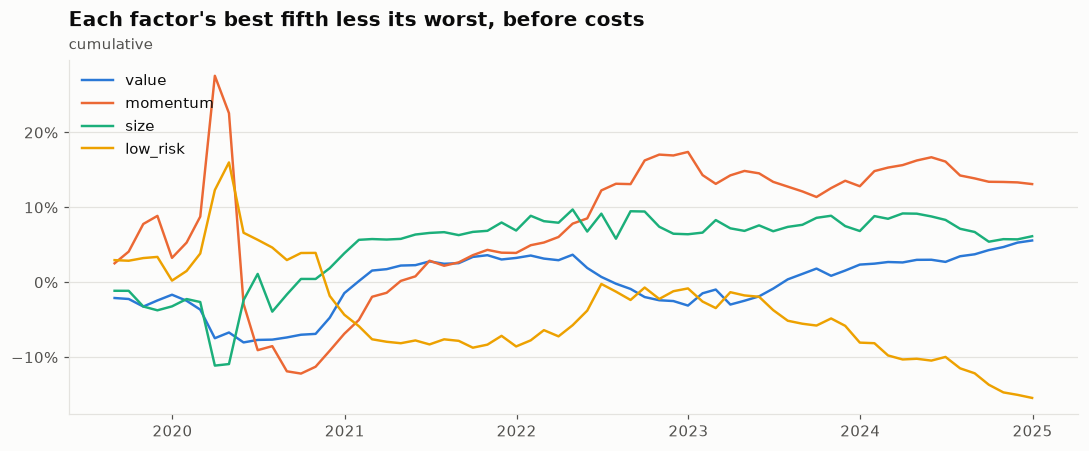

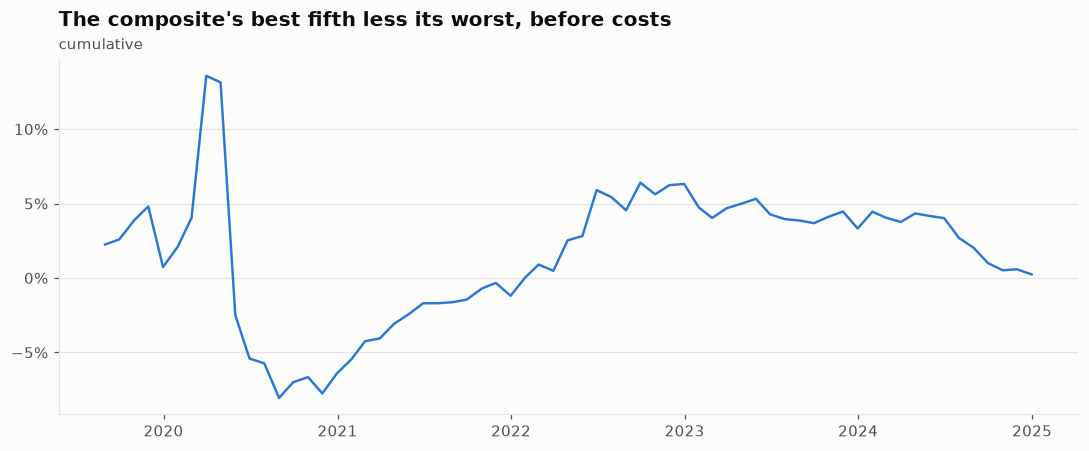

In [12]:
cumulative = (1 + spread).cumprod() - 1
fig = charts.lines(
    {k: cumulative[k] for k in FACTORS},
    "Each factor's best fifth less its worst, before costs",
    subtitle="cumulative",
    percent=True,
)
fig = charts.lines(
    {"composite": cumulative["composite"]},
    "The composite's best fifth less its worst, before costs",
    subtitle="cumulative",
    percent=True,
)

## Step 8 · What the best fifth bets on: industries

The returns say *whether* a signal worked; its weights say *what it was betting on*. The **active weight** of an
industry is the fifth's weight in it less the index's, at each rebalance: +5 % means the fifth holds five points more
of that industry than the index does. A value signal that is a lasting bet on one industry is a common way factor
models disappoint. Industries are ICE's level 3, of the issuer that month.

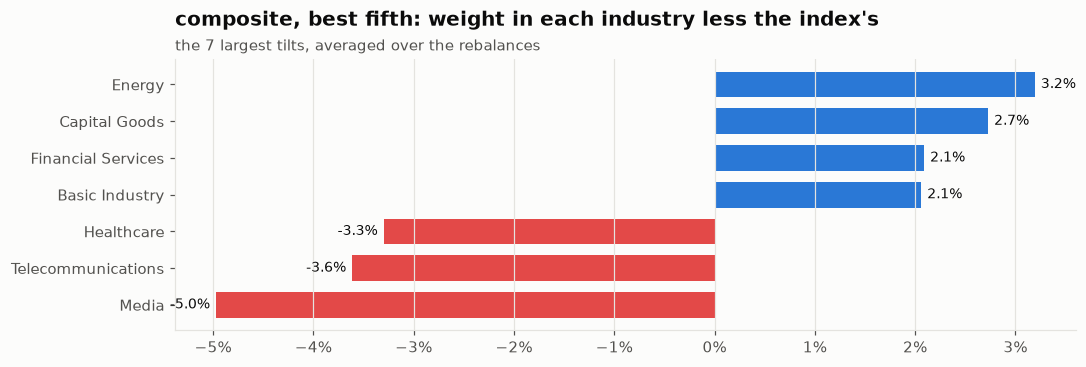

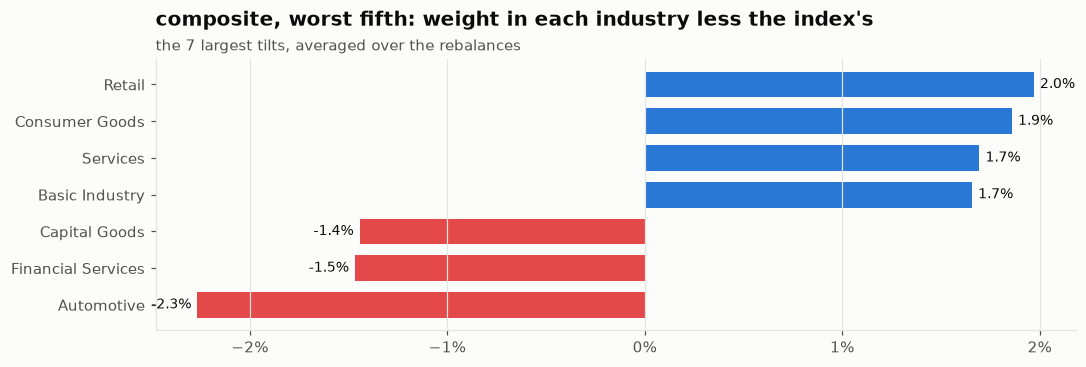

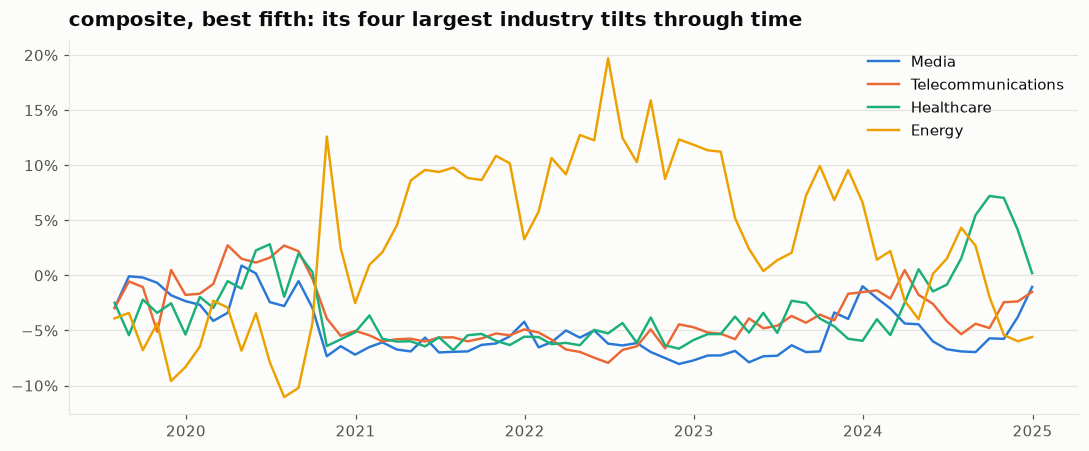

In [13]:
best_tilt = fs.active_weights(run, DIAG_SIGNAL, TOP, data.industry)
worst_tilt = fs.active_weights(run, DIAG_SIGNAL, 1, data.industry)
for label, tilt in (("best", best_tilt), ("worst", worst_tilt)):
    mean = tilt.mean()
    fig = charts.ranked_bars(
        mean[mean.abs().nlargest(TOP_N).index],
        f"{DIAG_SIGNAL}, {label} fifth: weight in each industry less the index's",
        subtitle=f"the {TOP_N} largest tilts, averaged over the rebalances",
        percent=True,
    )
largest = best_tilt.mean().abs().nlargest(4).index
fig = charts.lines(
    {k: best_tilt[k] for k in largest},
    f"{DIAG_SIGNAL}, best fifth: its four largest industry tilts through time",
    percent=True,
)

## Step 9 · What the best fifth bets on: ratings

The same by rating band - the one to watch in high yield. A best fifth that is persistently overweight CCCs is paid
for **taking credit risk**, not for choosing bonds, and shows it as a drawdown the first time spreads gap wider. The
table gives every fifth's average active weight per band; the chart the best fifth's through time.

,BBB,BB,B,CCC and below
fifth,,,,
1,-0.0%,-26.8%,+7.4%,+19.5%
2,-0.0%,-4.9%,+2.0%,+2.9%
3,-0.0%,+0.8%,+0.2%,-0.9%
4,+0.0%,+8.7%,-4.5%,-4.2%
5,-0.0%,+8.4%,-4.7%,-3.7%
index weight,+0.0%,+52.3%,+36.2%,+11.5%


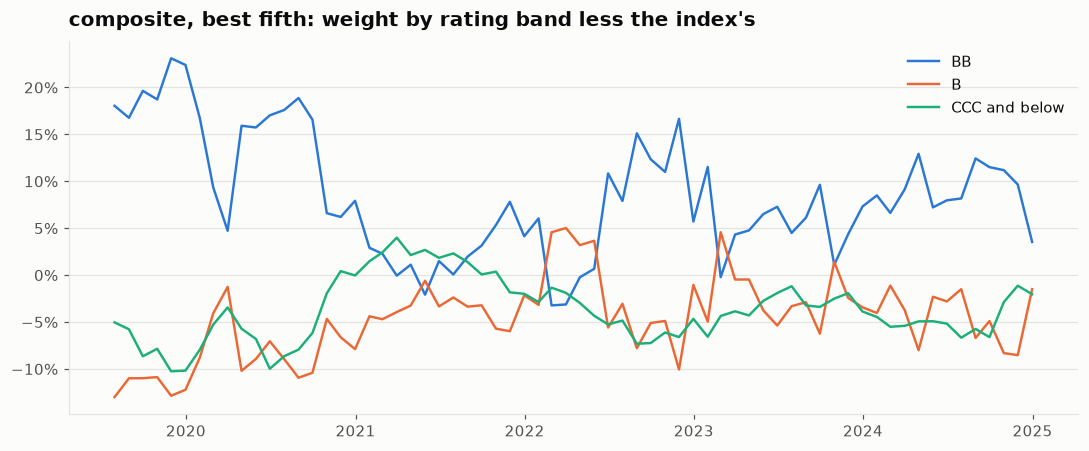

In [14]:
bands = broad_rating(data.rating)
by_fifth = pd.DataFrame({q: fs.active_weights(run, DIAG_SIGNAL, q, bands).mean() for q in range(1, TOP + 1)}).T
by_fifth = by_fifth[[b for b in BANDS if b in by_fifth.columns]].rename_axis("fifth")
index_mix = rp.weight_by_group(data.weights.loc[run.dates].fillna(0.0), bands).mean()
by_fifth.loc["index weight"] = index_mix.reindex(by_fifth.columns)
display(by_fifth.style.format("{:+.1%}").set_caption(f"{DIAG_SIGNAL}: weight by rating band less the index's"))
best_bands = fs.active_weights(run, DIAG_SIGNAL, TOP, bands)
shown = [b for b in BANDS if b in best_bands.columns and best_bands[b].abs().mean() > 0.005]
fig = charts.lines(
    {b: best_bands[b] for b in shown},
    f"{DIAG_SIGNAL}, best fifth: weight by rating band less the index's",
    percent=True,
)

## Step 10 · Today's ranking

The bonds of the latest file, best composite first, with each signal's percentile among that month's members (100 %
the best). This reads every file, the hold-out's included: a ranking of today's bonds is not a backtest and measures
nothing. It is the list a portfolio manager reads to see *which* bonds the model likes.

In [15]:
latest = load_index_data(cache, INDEX)
today = latest.dates[-1]
issuers = cache.query("SELECT issuer_id, name FROM core.issuer").set_index("issuer_id")["name"]
ranking = fs.screen(latest, fs.factor_scores(latest, config), today, issuers)
print(f"{len(ranking):,} bonds in {INDEX} on {today:%d %B %Y}; the {SCREEN_ROWS} the composite likes most:")
display(
    ranking.head(SCREEN_ROWS).style.format(
        {"years": "{:.1f}", "oas_bp": "{:,.0f}", "weight": "{:.3%}"} | {k: "{:.0%}" for k in SIGNALS}, na_rep="-"
    )
)

1,890 bonds in H0A0 on 31 July 2026; the 20 the composite likes most:


,bond,issuer,rating,industry,years,oas_bp,weight,value,momentum,size,low_risk,composite
listing_id,,,,,,,,,,,,
8918,Resorts World Las Vegas LLC / RWLV Capital Inc.,Resorts World Las Vegas Llc / Rwlv Cap Inc,BB1,Leisure,2.7,452,0.062%,97%,84%,58%,93%,100%
10234,Dentsply Sirona Inc,Dentsply Sirona Inc,BB1,Healthcare,4.1,355,0.039%,99%,98%,87%,75%,100%
8661,Organon & Co,Organon & Co,BB2,Healthcare,1.7,79,0.142%,98%,73%,22%,96%,100%
8424,Hilcorp Energy I L.P/Hilcorp Finance Co,Hilcorp Energy I L.P/Hilcorp Finance Co,BB2,Energy,2.5,149,0.041%,95%,79%,20%,92%,100%
9645,INEOS Finance PLC,Ineos Group Holdings S.A.,BB3,Basic Industry,2.7,387,0.049%,82%,99%,69%,84%,100%
8816,SunCoke Energy Inc.,SunCoke Energy Inc.,BB3,Basic Industry,2.9,227,0.033%,95%,87%,92%,80%,100%
9610,Hudson Pacific Properties LP,Hudson Pacific Properties LP,B1,Real Estate,1.5,236,0.024%,97%,75%,58%,88%,100%
9931,Genting New York LLC / Genny Cap Inc.,Genting New York Llc / Genny Cap Inc,BB1,Leisure,3.2,156,0.045%,94%,79%,84%,88%,100%
9639,Aag FH UK Ltd & Global Auto Holdings UK Ltd.,Aag FH UK Ltd & Global Auto Holdings UK Ltd.,B2,Retail,2.5,430,0.036%,99%,86%,57%,76%,100%


## Step 11 · The workbook

One workbook with the settings of the run (and its registered ids), every fifth's monthly return, the tables above
and today's ranking, in the fixed income research folder of the database's data folder.

In [16]:
if EXPORT:
    folder = get_settings().data_dir / "research" / "fixed_income"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"credit_factors_{INDEX}_{dt.date.today():%Y%m%d}.xlsx"
    settings = pd.Series(
        {k: str(v) for k, v in asdict(config).items()}
        | {"research runs": str(run.run_ids), "written": f"{dt.datetime.now():%Y-%m-%d %H:%M}"},
        name="value",
    )
    monthly = pd.concat(
        {f"{name} fifth {q}": r.net for name, fifths in run.backtests.items() for q, r in fifths.items()}
        | {"index": run.benchmark, "all members equally": run.equal_weighted.net},
        axis=1,
    )
    with pd.ExcelWriter(path) as xl:
        settings.to_frame().to_excel(xl, sheet_name="settings")
        monthly.to_excel(xl, sheet_name="monthly returns")
        table.to_excel(xl, sheet_name="fifths after costs")
        spread_stats.to_excel(xl, sheet_name="best less worst")
        ledger.to_excel(xl, sheet_name="information coefficients")
        pd.concat({f"+{h} month(s)": m for h, m in transitions.items()}).to_excel(xl, sheet_name="transitions")
        by_fifth.to_excel(xl, sheet_name="rating tilts")
        ranking.to_excel(xl, sheet_name=f"ranking {today:%Y-%m-%d}")
    print(f"Saved {path}")

Saved C:\SourceCode\QuantResearch\data\quant_research_local\research\fixed_income\credit_factors_H0A0_20261120.xlsx


## Findings

Results as of the run above: `H0A0`, 66 monthly rebalances from July 2019 to December 2024 (65 months of returns),
fifths equally weighted, excess returns, 25 bp a trade; the composite of value, momentum and low risk a third each,
size left out; research runs 262 to 266.

* **Value sorts the bonds, but not at the extremes.** Its information coefficient is the only one to clear the bar:
  +0.042 a month, t 3.42, a discovery after the false-discovery control across the five signals. Yet its fifths do not
  fan out: before costs the middle three beat the index by 0.7 to 1.9 % a year while the best fifth trails it by 0.4 %,
  so the best less worst is +0.8 % a year (t 0.67). Its book turns over 7.8 times a year, about 2 % a year at 25 bp a
  trade: after costs its best fifth trails the index by 2.3 %. Its fit has a dummy per rating notch, so its best fifth
  holds the index's mix of ratings; its worst holds 10 points more CCC.
* **Momentum's result rests on March 2020.** Its best fifth beat the index by 3.3 % a year before costs and 1.1 % after,
  and grew 5.0 % a year faster than its worst fifth; but its IC (t 1.47) and its monthly spread (t 0.56) are short of
  the bar, and without March and April 2020 the mean spread falls from 3.2 % to 0.7 % a year. The spread is volatile
  (13 % a year: -9.8 % in 2020, +11.6 % in 2021, +13.0 % in 2022) and its best fifth is a credit bet: 14 points more CCC
  than the index, beta 1.12.
* **Small issuers did better, holding more CCCs.** The size factor's best fifth beat the index by 1.3 % a year after
  costs, with little trading (turnover 1.7) - but with beta 1.23, 24 points less BB and 15 more CCC than the index; its
  IC (t 1.50) and spread (t 0.43) are not significant.
* **Low risk worked backwards.** The safe fifth trailed the index by 0.8 % a year after costs and the risky fifth beat
  it by 1.2 % (IC -0.046, t -1.76): these years paid for credit risk. The safe fifth was the steadiest - volatility
  7.3 % against the index's 8.8 %, beta 0.81, a worst fall of 15.7 % against 18.0 % - but per unit of risk no better
  than the index (Sharpe 0.41 against 0.45), which is the factor's claim.
* **The composite adds nothing.** The factors rank the bonds almost independently (correlations -0.06 to +0.09), and
  low risk, a third of the mix, worked backwards and cancels much of the other two: the composite's best fifth beat
  the index by 1.0 % a year before costs and its worst trailed it by 0.2 %, but the IC is +0.011 (t 0.61) and the
  monthly spread is noise (t 0.11; -7.1 % in 2020, +5.6 % in 2021, +7.6 % in 2022, about -3 % in 2023 and 2024).
  After costs (turnover 7.4 a year) the best fifth trails the index by 0.9 % a year. Without size the composite leans
  to quality: its best fifth holds 8.4 points more BB and 3.7 fewer CCC than the index (beta 0.95, worst fall 19.3 %),
  its worst fifth 27 points less BB and 20 more CCC; by industry the best fifth leans to energy (+3.2 points),
  capital goods (+2.7), financial services and basic industry (+2.1 each), away from media (-5.0),
  telecommunications (-3.6) and healthcare (-3.3). It is persistent: 72 % of the best fifth is still in it a month
  later, 60 % three months later. With all four factors at equal weights (run 261) the result was much the same: best
  fifth -0.7 % a year after costs, IC +0.020 (t 1.03).
* **Nothing is convincing yet.** No best fifth's deflated active Sharpe ratio comes near 95 % (momentum 31 %, size
  29 %, the other three 2 % or less), with six variants of the family registered. Sixty-five months are few: the
  composite's weights are an interim choice until ICE's files from 2005 are loaded, and should be fixed before the
  longer history is run rather than chosen from it.
* **The machinery holds.** The index book matches notebook 2.1's rebuild to 5e-8 a month; no score moves when the later
  files are deleted; the engine's return for a book equals its bonds' returns in the next file worked by hand
  (-0.9615 % in May 2022). On average 1.9 % of the index's weight leaves each month and earns the index's return.

## Limits

* **Five and a half years.** ICE's files begin in January 2019, so the backtest has 65 months. A credit factor premium
  of one or two percent a year, with a tracking error of a few percent, takes decades of months to tell from luck:
  read the t-statistics and the deflated ratios, not the averages alone. More history needs more of ICE's month-end
  files (`fir load-ice` takes them in any order).
* **The hold-out is closed.** January 2025 to today is kept for one test of a final strategy (`OPEN_HOLDOUT`); the
  month after the missing April 2025 file could not be measured there either.
* **Fifths test a signal; they are not portfolios.** About 380 bonds each, equally weighted, with no duration or
  spread-duration matching and no issuer or industry limits. Trading costs are one flat assumption, where a desk pays
  more for small, illiquid and distressed bonds - the ones size and value prefer.
* **Bonds that leave** earn the index's return over their last month, in every book alike; a fifth heavy in bonds
  that defaulted is flattered.
* **Fixed weights.** The composite's weights do not change with the market; time-varying factor weights (a regime
  overlay) would need their own, registered, rules.
* **The provider's view of each bond.** Ratings are ICE's composite ratings and industries ICE's level 3, both as of
  each month end; excess returns are ICE's, over duration-matched Treasuries.

## Glossary

* **Option-adjusted spread (OAS)** - the extra yield over government bonds a bond pays once its call options are
  priced, in basis points: the market's price of its credit risk.
* **Excess return** - the bond's return less that of Treasuries of the same duration: what its credit earned.
* **Fifth (quintile)** - a fifth of the index's bonds by a signal; fifth 5 the bonds it likes most.
* **Active return, tracking error, information ratio** - see step 4.
* **Information coefficient (IC)** - the rank correlation between a signal and the return that follows.
* **Deflated Sharpe ratio** - the probability that a Sharpe ratio reflects skill, given how many variants were tried.
* **Hold-out** - the most recent months, kept for a single out-of-sample test.
* **Basis point (bp)** - one hundredth of a percent.